<a href="https://colab.research.google.com/github/khanrumnaz19-glitch/beach-drowning-detection/blob/main/notebooks/01_data_prep.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q ultralytics roboflow imagehash

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.0/47.0 kB 1.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 11.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 373.9/373.9 kB 24.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 21.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 4.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 51.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.9/97.9 kB 7.9 MB/s eta 0:00:00


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
from google.colab import userdata
from roboflow import Roboflow

rf = Roboflow(api_key=userdata.get('ROBOFLOW_KEY'))
project = rf.workspace('rumnazs-capstone-project').project('swimming-and-drowning-detection-eocho')
dataset = project.version(1).download('yolov8', location='/content/drive/MyDrive/capstone/data/sdd_clean')

loading Roboflow workspace...
loading Roboflow project...
Exporting format yolov8 in progress : 95.0%
Version export complete for yolov8 format



Extracting Dataset Version Zip to /content/drive/MyDrive/capstone/data/sdd_clean in yolov8:: 100%|██████████| 14594/14594 [03:50<00:00, 63.23it/s]


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


In [4]:
import pathlib
DATA = pathlib.Path('/content/drive/MyDrive/capstone/data/sdd_clean')
total = 0
for split in ['train', 'valid', 'test']:
    n = len(list((DATA / split / 'images').glob('*')))
    total += n
    print(split, n, 'images')
print('TOTAL', total)
print(open(DATA / 'data.yaml').read())

train 5070 images
valid 1478 images
test 747 images
TOTAL 7295
names:
- Drowning
- Person out of water
- Swimming
nc: 3
roboflow:
  license: CC BY 4.0
  project: swimming-and-drowning-detection-eocho
  url: https://app.roboflow.com/rumnazs-capstone-project/swimming-and-drowning-detection-eocho/1
  version: 1
  workspace: rumnazs-capstone-project
test: ../test/images
train: ../train/images
val: ../valid/images



In [5]:
import collections
names = ['Drowning', 'Person out of water', 'Swimming']
box_count = collections.Counter()
size_count = collections.Counter()
for split in ['train', 'valid', 'test']:
    for f in (DATA / split / 'labels').glob('*.txt'):
        for line in f.read_text().splitlines():
            parts = line.split()
            if len(parts) < 5: continue
            c, w, h = int(parts[0]), float(parts[3]), float(parts[4])
            box_count[names[c]] += 1
            area = w * h      # fraction of the image the box covers
            size_count['small (<1%)' if area < 0.01 else 'medium (1-10%)' if area < 0.10 else 'large (>10%)'] += 1
print('Boxes per class:', dict(box_count))
print('Box sizes:', dict(size_count))


Boxes per class: {'Swimming': 5371, 'Drowning': 7801, 'Person out of water': 477}
Box sizes: {'medium (1-10%)': 7592, 'small (<1%)': 2890, 'large (>10%)': 3167}


In [6]:
import re, random
def original_name(p):
    return re.split(r'_(jpg|jpeg|png)\.rf\.', p.name, flags=re.I)[0]
all_imgs = [p for s in ['train', 'valid', 'test'] for p in (DATA / s / 'images').glob('*')]
random.seed(0)
for p in random.sample(all_imgs, 40):
    print(original_name(p))

drowning55_mp4_mp4-12
86_png
drowning1_mp4-19
130413
youtube-34
youtube-24
video_2022-12-07_23-08-12_mp4-13
drowning54_mp4_mp4-1
drowning2
92_png
images-6-_jpeg
84
drowning1_mp4-23
youtube-2
video_2022-12-07_23-08-15_mp4-11
drowning51_mp4_mp4-23
drowning52_mp4_mp4-41
youtube-92
drowning1_mp4-14
youtube-5
drowning1_mp4-15
159_png
59_png
drowning50_mp4_mp4-8
3101
image1006
136
youtube-5
youtube-35
drowning51_mp4_mp4-26
image3727
video_2022-12-07_23-08-12_mp4-17
drowning55_mp4_mp4-4
134653437-asian-senior-people-struggling-underwater-hand-peeking-out-of-the-water-female-drowned-in-swimming-p
202_png
youtube-124
drowning2_1559613029952_90596921_ver1-0
drowning47_mp4-9
drowning_40_0_2921_jpeg
200_png


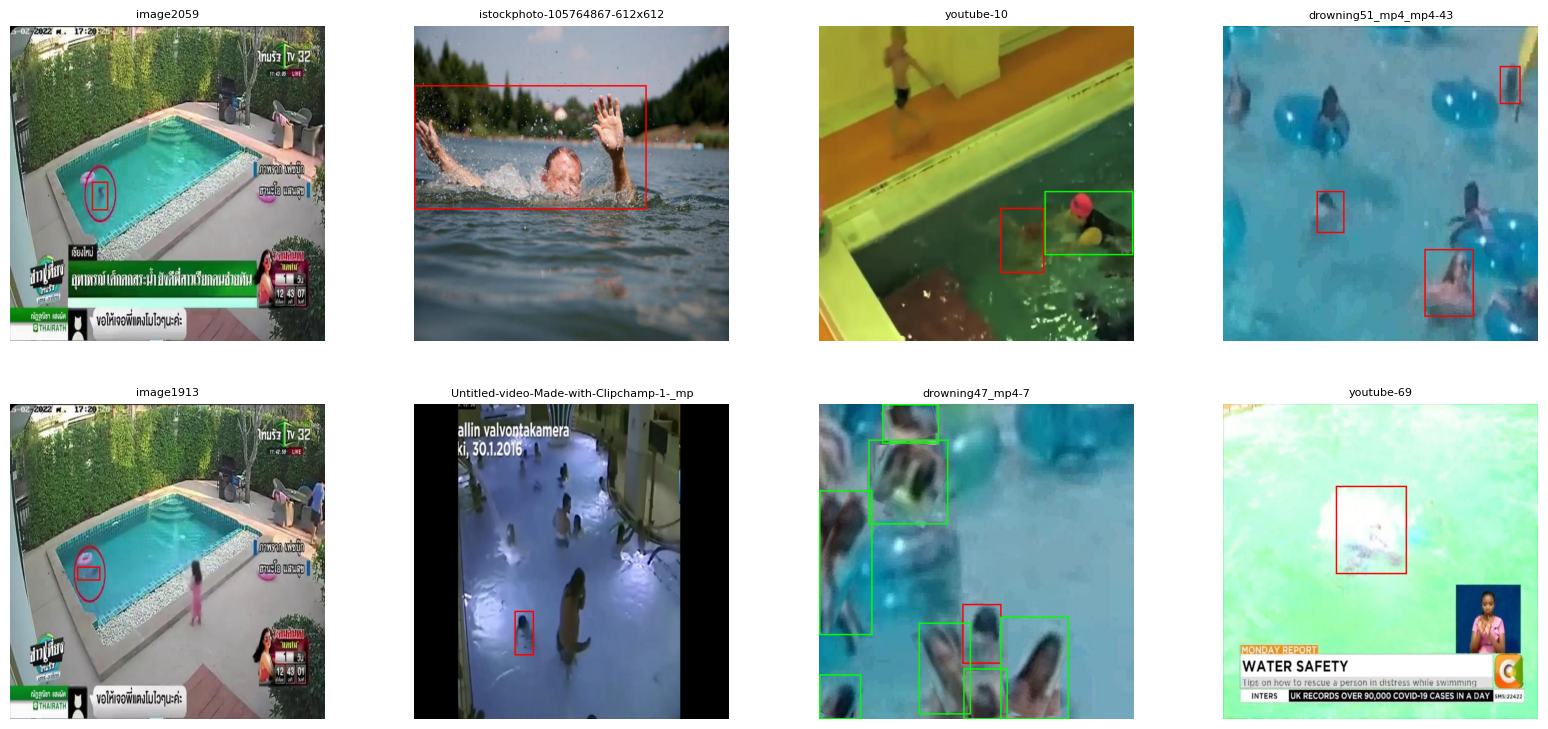

In [7]:
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
colors = ['red', 'yellow', 'lime']
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for ax, p in zip(axes.flat, random.sample(all_imgs, 8)):
    im = Image.open(p).convert('RGB'); W, H = im.size; d = ImageDraw.Draw(im)
    lbl = p.parent.parent / 'labels' / (p.stem + '.txt')
    for line in lbl.read_text().splitlines():
        c, x, y, w, h = map(float, line.split()[:5])
        d.rectangle([(x-w/2)*W, (y-h/2)*H, (x+w/2)*W, (y+h/2)*H], outline=colors[int(c)], width=3)
    ax.imshow(im); ax.set_title(original_name(p)[:40], fontsize=8); ax.axis('off')
plt.show()

In [8]:
import imagehash, numpy as np
from tqdm import tqdm
H = np.array([imagehash.phash(Image.open(p).convert('L')).hash.flatten() for p in tqdm(all_imgs)])
print(H.shape)

100%|██████████| 7295/7295 [01:13<00:00, 98.85it/s] 

(7295, 64)


In [12]:
parent = list(range(len(all_imgs)))
def find(i):
    while parent[i] != i:
        parent[i] = parent[parent[i]]; i = parent[i]
    return i
def union(a, b):
    parent[find(a)] = find(b)

# Rule 1: same video name, e.g. drowning51_mp4_mp4-23 -> drowning51_mp4
first_of = {}
for i, p in enumerate(all_imgs):
    m = re.match(r'(.+?_mp4)', original_name(p))
    if m:
        k = m.group(1)
        if k in first_of: union(i, first_of[k])
        else: first_of[k] = i

# Rule 2: nearly identical images (fingerprints differ by <= THRESH of 64 bits)
THRESH = 4
for i in range(len(H)):
    close = np.nonzero((H[i+1:] != H[i]).sum(1) <= THRESH)[0]
    for j in close:
        union(i, i + 1 + j)

groups = collections.defaultdict(list)
for i, p in enumerate(all_imgs):
    groups[find(i)].append(p)
sizes = sorted((len(v) for v in groups.values()), reverse=True)
print(len(groups), 'groups')
print('10 largest groups:', sizes[:10])
print('groups with only 1 image:', sum(s == 1 for s in sizes))
cross = sum(1 for v in groups.values() if len({p.parent.parent.name for p in v}) > 1)
print(cross, "groups are spread across more than one of Roboflow's train/valid/test")

2138 groups
10 largest groups: [863, 629, 520, 233, 207, 207, 199, 189, 153, 127]
groups with only 1 image: 1672
275 groups are spread across more than one of Roboflow's train/valid/test


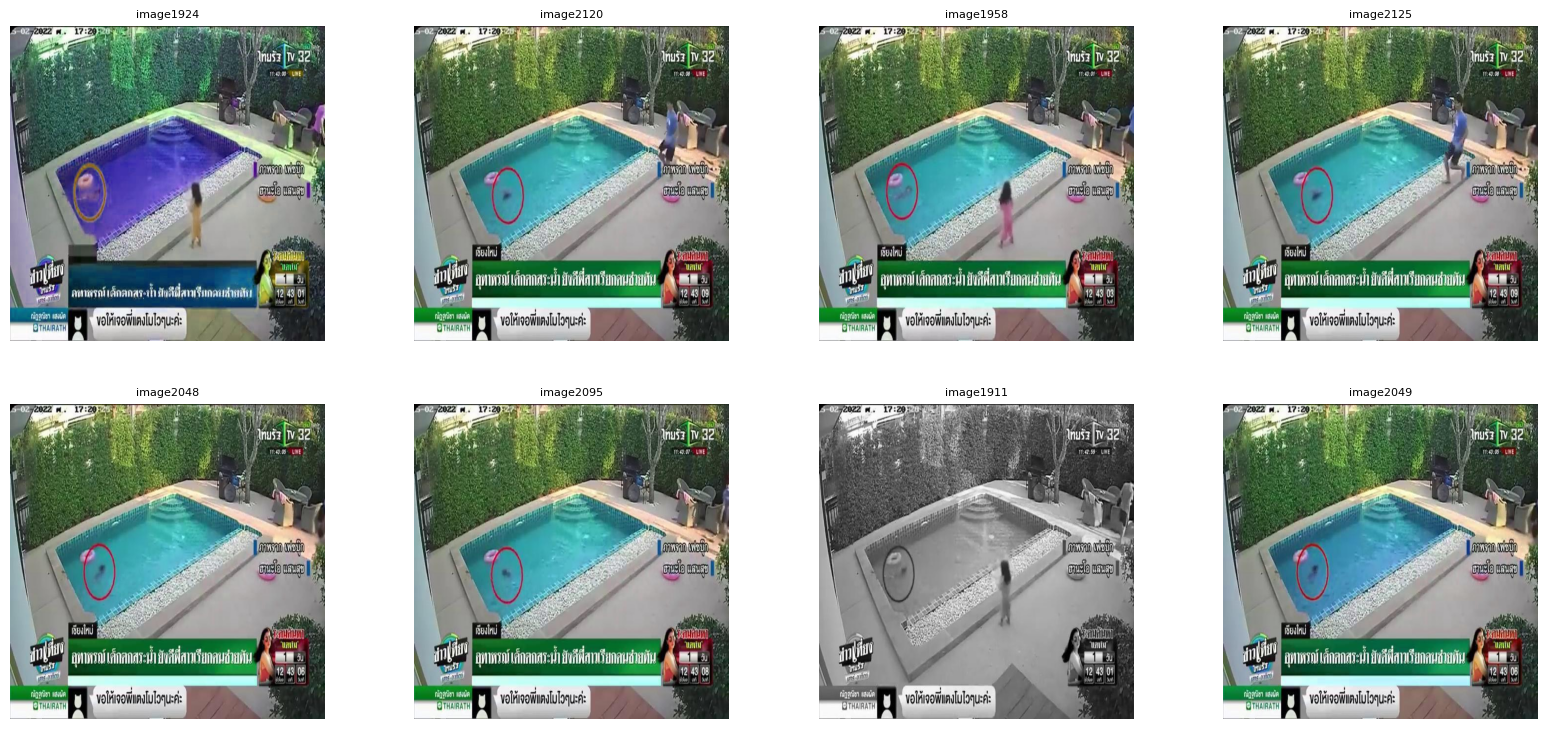

In [17]:
big = sorted(groups.values(), key=len, reverse=True)[0]
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for ax, p in zip(axes.flat, random.sample(big, min(8, len(big)))):
    ax.imshow(Image.open(p)); ax.set_title(original_name(p)[:40], fontsize=8); ax.axis('off')
plt.show()

In [16]:
# Rule 3: attach leftover frames of the big videos.
# Looser match (<= 10 bits), but ONLY to images already in a big group -> no chaining.
glist = sorted(groups.values(), key=len, reverse=True)
idx = {p: i for i, p in enumerate(all_imgs)}
big_ids = [idx[p] for g in glist if len(g) > 300 for p in g]
big_set = set(big_ids)
Hb = H[big_ids]
moved = 0
for i in range(len(all_imgs)):
    if i in big_set:
        continue
    d = (Hb != H[i]).sum(1)
    j = d.argmin()
    if d[j] <= 10 and find(i) != find(big_ids[j]):
        union(i, big_ids[j]); moved += 1

groups = collections.defaultdict(list)
for i, p in enumerate(all_imgs):
    groups[find(i)].append(p)
sizes = sorted((len(v) for v in groups.values()), reverse=True)
print('attached', moved, 'images to big videos')
print(len(groups), 'groups; 10 largest:', sizes[:10])

attached 10 images to big videos
2128 groups; 10 largest: [871, 836, 613, 233, 207, 207, 189, 153, 127, 110]


In [18]:
import csv
glist = sorted(groups.values(), key=len, reverse=True)
with open(DATA / 'groups_thresh4.csv', 'w', newline='') as f:
    w = csv.writer(f); w.writerow(['image', 'group', 'roboflow_split'])
    for gid, g in enumerate(glist):
        for p in g:
            w.writerow([str(p), gid, p.parent.parent.name])
print('saved')

saved


In [19]:
random.seed(0)
big  = [g for g in glist if len(g) > 300]     # very large videos -> train only
rest = [g for g in glist if len(g) <= 300]
random.shuffle(rest)
n = len(all_imgs)
split = {'train': [p for g in big for p in g], 'val': [], 'test': []}
for g in rest:
    if   len(split['test']) < 0.15 * n: split['test'] += g
    elif len(split['val'])  < 0.15 * n: split['val']  += g
    else:                               split['train'] += g

def class_counts(files):
    c = collections.Counter()
    for p in files:
        for line in (p.parent.parent / 'labels' / (p.stem + '.txt')).read_text().splitlines():
            if line.strip(): c[names[int(line.split()[0])]] += 1
    return dict(c)

for s, files in split.items():
    print(f'{s:5s} {len(files):5d} images ({len(files)/n:.0%})  boxes: {class_counts(files)}')

train  5080 images (70%)  boxes: {'Drowning': 4987, 'Person out of water': 255, 'Swimming': 3567}
val    1106 images (15%)  boxes: {'Swimming': 994, 'Drowning': 1389, 'Person out of water': 97}
test   1109 images (15%)  boxes: {'Person out of water': 125, 'Swimming': 810, 'Drowning': 1425}


In [20]:
gid_of = {p: find(i) for i, p in enumerate(all_imgs)}
S = {s: {gid_of[p] for p in files} for s, files in split.items()}
assert not (S['train'] & S['val']) and not (S['train'] & S['test']) and not (S['val'] & S['test'])
print('No source appears in two splits ✔')

import yaml
for s, files in split.items():
    (DATA / f'split_{s}.txt').write_text('\n'.join(str(p) for p in files))
cfg = {'train': str(DATA / 'split_train.txt'),
       'val':   str(DATA / 'split_val.txt'),
       'test':  str(DATA / 'split_test.txt'),
       'names': {0: 'Drowning', 1: 'Person out of water', 2: 'Swimming'}}
yaml.safe_dump(cfg, open(DATA / 'data_videosplit.yaml', 'w'), sort_keys=False)
print(open(DATA / 'data_videosplit.yaml').read())

No source appears in two splits ✔
train: /content/drive/MyDrive/capstone/data/sdd_clean/split_train.txt
val: /content/drive/MyDrive/capstone/data/sdd_clean/split_val.txt
test: /content/drive/MyDrive/capstone/data/sdd_clean/split_test.txt
names:
  0: Drowning
  1: Person out of water
  2: Swimming

